# ML6 — Customer map and segments

**Project:** DS 5020 Mini-Project "Customers Like You".

Inputs (read-only, **training data only**): `A_log.npz`, `customer_index.parquet`, `product_index.parquet`,
`train.parquet` (for spend, invoices, country). Code: `src/segments.py`, reusing `src/svd.py`.

Steps

1. `TruncatedSVD(50, randomized, n_iter=7, seed 42)` on `A_log`; customer vectors `U*Sigma = svd.transform(A_log)`.
2. Component 1 is overall buying volume (ML2 / ML5) and would dominate any map, so each customer vector is scaled to
   unit L2 length. What is left is the *mix* of products a customer buys, not how much.
3. k-means (`n_init=20`, seed 42) on the unit-norm 50-dim vectors for 3, 4, 5, 6 clusters; silhouette on a 3,000-customer
   sample (seed 42) and cluster sizes. **The number of clusters is not chosen here.**
4. Segment profiles per `n_clusters` → `reports/ml6_segments_k{n}.csv`.
5. Two 2-D maps per `n_clusters` → `reports/figures/ml6_map_k{n}.png`.

Segments are numbered by size (Segment 1 = largest) so tables and figures agree. Segment names are left blank.
No customer IDs or row indices appear in any output.

In [1]:
# Environment guard: this notebook must run in the "giftlane" conda env (pandas 3.0.6).
# It fails fast with "Wrong Python environment. Run: conda activate giftlane" otherwise.
import sys
from pathlib import Path

_ROOT = Path.cwd().resolve()
if _ROOT.name == "notebooks":
    _ROOT = _ROOT.parent
if str(_ROOT) not in sys.path:
    sys.path.insert(0, str(_ROOT))

from src.env_check import check_env

print("environment OK:", check_env())

environment OK: /opt/homebrew/Caskroom/miniforge/base/envs/giftlane/bin/python3.11


## 0. Setup, SVD fit, customer vectors

In [2]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
import numpy as np
import pandas as pd
import scipy.sparse as sp
import sklearn

from src.svd import SEED, N_ITER, load_inputs, fit_svd, top_products_for_component
from src.segments import (
    CLUSTER_GRID, MIN_CLUSTER_SHARE, N_INIT, N_SIGNATURE, SILHOUETTE_SAMPLE,
    centroids_2d, cluster_sweep, component_axis_words, customer_stats, customer_vectors, normalise_rows,
    project_2d, projection_axis_words, save_profiles, segment_profiles, spread_labels, volume_correlations,
)

ROOT = _ROOT
PROCESSED = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 60)

K = 50
A_log, product_index, customer_index = load_inputs(ROOT)
train = pd.read_parquet(PROCESSED / "train.parquet")
n, m = A_log.shape
print("python  :", sys.executable)
print(f"sklearn : {sklearn.__version__} | numpy : {np.__version__} | pandas : {pd.__version__}")
print(f"A_log   : {n:,} x {m:,}, nnz {A_log.nnz:,} | train.parquet {len(train):,} rows (training period only)")
assert (n, m) == (5471, 3687) and A_log.nnz == 413706, "frozen matrix changed?"

svd, fit_s = fit_svd(A_log, K, seed=SEED, n_iter=N_ITER)
X_raw = customer_vectors(svd, A_log)      # U * Sigma, (n, 50)
X_unit = normalise_rows(X_raw)            # unit L2 rows
row_norms = np.linalg.norm(X_unit, axis=1)
print(f"SVD k={K} fitted in {fit_s:.3f}s; customer vectors {X_raw.shape}; unit-norm rows: min {row_norms.min():.6f}, max {row_norms.max():.6f}")
assert np.allclose(row_norms, 1.0), "some customer vector has zero length"
print(f"(for orientation) component 1 top products: " + "; ".join(top_products_for_component(svd, product_index, 0, 5)["Description"].str.strip()))

python  : /opt/homebrew/Caskroom/miniforge/base/envs/giftlane/bin/python
sklearn : 1.9.1 | numpy : 2.4.6 | pandas : 3.0.6
A_log   : 5,471 x 3,687, nnz 413,706 | train.parquet 659,830 rows (training period only)
SVD k=50 fitted in 0.104s; customer vectors (5471, 50); unit-norm rows: min 1.000000, max 1.000000
(for orientation) component 1 top products: PACK OF 72 RETRO SPOT CAKE CASES; WHITE HANGING HEART T-LIGHT HOLDER; JUMBO BAG RED RETROSPOT; LUNCH BAG RED RETROSPOT; 60 TEATIME FAIRY CAKE CASES


## 1. Does normalising remove volume?

Correlation between the component-1 score and the number of distinct products a customer bought in train
(row non-zeros of `A_log`), before and after scaling each vector to unit length.

In [3]:
corr = volume_correlations(X_raw, X_unit, A_log)
print(corr.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print("Reading: on raw U*Sigma, component 1 is almost a count of what the customer buys (r ~ 0.9).")
print("After unit-normalising, component 1 becomes the cosine between the customer's mix and the 'typical basket'")
print("direction; its linear relation to volume drops, although heavier buyers still tend to look more typical (rank corr stays high).")

    vectors  pearson_r(component1, n_products)  spearman_rho(component1, n_products)  component1_min  component1_max
raw U*Sigma                             0.8903                                0.9091          0.0007        132.4994
  unit-norm                             0.6824                                0.8808          0.0497          0.8398

Reading: on raw U*Sigma, component 1 is almost a count of what the customer buys (r ~ 0.9).
After unit-normalising, component 1 becomes the cosine between the customer's mix and the 'typical basket'
direction; its linear relation to volume drops, although heavier buyers still tend to look more typical (rank corr stays high).


## 2. k-means sweep on the unit-norm vectors

`KMeans(n_clusters=n, n_init=20, random_state=42)` for n = 3, 4, 5, 6. Silhouette is computed on a random sample of
3,000 customers (seed 42) with Euclidean distance (on unit vectors this is monotone in cosine distance).
Silhouettes on sparse purchase data are typically small; they are reported for comparison between n, not as an
absolute quality grade. **No n is selected here.**

In [4]:
sweep, labels_by_n = cluster_sweep(X_unit, grid=CLUSTER_GRID, seed=SEED, n_init=N_INIT, verbose=False)
print(f"silhouette: sample {SILHOUETTE_SAMPLE:,} customers, seed {SEED}; n_init={N_INIT}, random_state={SEED}")
print(sweep.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
for n_clusters, labels in labels_by_n.items():
    sizes = pd.Series(labels).value_counts().sort_index()
    print(f"n_clusters={n_clusters}: " + " | ".join(f"Segment {s}: {c:,} ({100*c/len(labels):.1f}%)" for s, c in sizes.items()))

silhouette: sample 3,000 customers, seed 42; n_init=20, random_state=42
 n_clusters  silhouette   inertia                                 sizes  smallest_pct
          3      0.0447 4190.3485                   2,878 / 1,692 / 901       16.4687
          4      0.0479 4078.1941             2,279 / 1,601 / 810 / 781       14.2753
          5      0.0528 3971.5580     1,623 / 1,310 / 1,092 / 726 / 720       13.1603
          6      0.0501 3879.6569 1,387 / 1,058 / 970 / 715 / 706 / 635       11.6067

n_clusters=3: Segment 1: 2,878 (52.6%) | Segment 2: 1,692 (30.9%) | Segment 3: 901 (16.5%)
n_clusters=4: Segment 1: 2,279 (41.7%) | Segment 2: 1,601 (29.3%) | Segment 3: 810 (14.8%) | Segment 4: 781 (14.3%)
n_clusters=5: Segment 1: 1,623 (29.7%) | Segment 2: 1,310 (23.9%) | Segment 3: 1,092 (20.0%) | Segment 4: 726 (13.3%) | Segment 5: 720 (13.2%)
n_clusters=6: Segment 1: 1,387 (25.4%) | Segment 2: 1,058 (19.3%) | Segment 3: 970 (17.7%) | Segment 4: 715 (13.1%) | Segment 5: 706 (12.9%) | Segm

## 3. Per-customer facts from the training data

From `train.parquet` only: distinct products bought, total spend (`Quantity * Price`), distinct invoices, main
country (the country on most of the customer's lines; 12 customers have two countries). The table is indexed by
matrix row and the customer ID is dropped immediately after the join.

In [5]:
stats = customer_stats(train, customer_index)
assert len(stats) == n and "Customer ID" not in stats.columns
print(stats.drop(columns=["row"]).describe(percentiles=[0.25, 0.5, 0.75]).T.to_string(float_format=lambda v: f"{v:,.2f}"))
print()
print("country split (all customers):")
print((100 * stats["country"].value_counts(normalize=True).head(6)).round(1).to_string())

              count     mean       std  min    25%    50%      75%        max
n_products 5,471.00    76.31    108.25 1.00  18.00  42.00    93.00   2,355.00
spend      5,471.00 2,688.01 12,994.88 2.90 321.12 784.81 2,112.20 524,476.60
n_invoices 5,471.00     5.80     11.59 1.00   1.00   3.00     6.00     308.00

country split (all customers):
country
United Kingdom    91.3
Germany            1.8
France             1.5
Spain              0.6
Belgium            0.5
Netherlands        0.4


## 4. Segment profiles for each n_clusters

Per segment: size, share of customers, medians of products / spend / invoices, top 3 countries, and 10 **signature
products** ranked by lift = share of the segment who bought it ÷ share of all customers who bought it, restricted to
products bought by at least 10% of the segment (so a signature product is both distinctive *and* common inside the
segment). Saved to `reports/ml6_segments_k{n}.csv` (long form with a `section` column; `segment_name` left blank).

In [6]:
profiles = {}
for n_clusters, labels in labels_by_n.items():
    summary, sig, long = segment_profiles(labels, stats, A_log, product_index)
    path = save_profiles(long, ROOT, n_clusters)
    profiles[n_clusters] = (summary, sig)
    print("=" * 110)
    print(f"n_clusters = {n_clusters}      saved -> {path.relative_to(ROOT)}")
    print("=" * 110)
    print(summary.to_string(index=False, float_format=lambda v: f"{v:,.1f}"))
    for seg in summary["segment"]:
        s = sig.loc[sig["segment"] == seg]
        n_elig = int(s["n_eligible_products"].iloc[0]) if len(s) else 0
        print(f"\n  Segment {seg} - signature products (lift; {n_elig} products bought by >= {int(100*MIN_CLUSTER_SHARE)}% of the segment)")
        view = s[["rank", "StockCode", "Description", "segment_share_pct", "overall_share_pct", "lift"]]
        print("  " + view.to_string(index=False, float_format=lambda v: f"{v:.2f}").replace("\n", "\n  "))
    print()

n_clusters = 3      saved -> reports/ml6_segments_k3.csv
 segment segment_name  n_customers  pct_customers  median_products  median_spend  median_invoices                                   top_countries
       1                      2878           52.6             36.5         683.7              2.0 United Kingdom 89.0%; Germany 2.3%; France 1.8%
       2                      1692           30.9             41.0         737.3              3.0   United Kingdom 97.6%; Cyprus 0.3%; Spain 0.3%
       3                       901           16.5             71.0       1,607.0              5.0 United Kingdom 86.8%; France 3.2%; Germany 3.1%

  Segment 1 - signature products (lift; 36 products bought by >= 10% of the segment)
   rank StockCode                        Description  segment_share_pct  overall_share_pct  lift
      1     84077  WORLD WAR 2 GLIDERS ASSTD DESIGNS              10.56               7.73  1.37
      2     21791 VINTAGE HEADS AND TAILS CARD GAME               13.31        

## 5. Two-dimensional maps

Left panel: unit-norm **components 2 and 3** (component 1 is volume / typicality and is left out).
Right panel: a fresh `TruncatedSVD(n_components=2)` fitted on the unit-norm 50-dim vectors. Because those vectors are
not centred and all have positive component 1, the first projection axis mostly measures how *typical* a customer's
mix is, and the second separates the mixes; the plain-word axis labels come from mapping each axis back to product
space (`axis @ V`) and naming the products at its two ends.

Points are customers coloured by segment; "Segment i" sits at the segment's centroid in that view. No IDs anywhere.

2-D projection of the unit-norm vectors: explained variance ratio [0.0256, 0.0683], axis-1 range [0.042, 0.832], axis-2 range [-0.541, 0.618]

axis words (products at each end of the axis):
  x: Component 2 (volume removed) | ←  Lunch Bag Spaceboy Design, Round Snack Boxes Set Of4…    |    White Hanging Heart T-Lig…, Heart Of Wicker Small  →
  y: Component 3 (volume removed) | ↑ Jumbo Bag Red Retrospot, Jumbo Bag Pink Polkadot | ↓ Mini Paint Set Vintage, World War 2 Gliders Asstd…
  x: Projection axis 1 (how typical the mix is) | ←  Spaceboy Rocket Lolly Mak…, Blue  Voile Lampshade    |    White Hanging Heart T-Lig…, Assorted Colour Bird Orna…  →
  y: Projection axis 2 | ↑ White Hanging Heart T-Lig…, Assorted Colour Bird Orna… | ↓ Pack Of 72 Retro Spot Cak…, Lunch Bag Red Retrospot


saved -> reports/figures/ml6_map_k3.png


saved -> reports/figures/ml6_map_k4.png


saved -> reports/figures/ml6_map_k5.png


saved -> reports/figures/ml6_map_k6.png


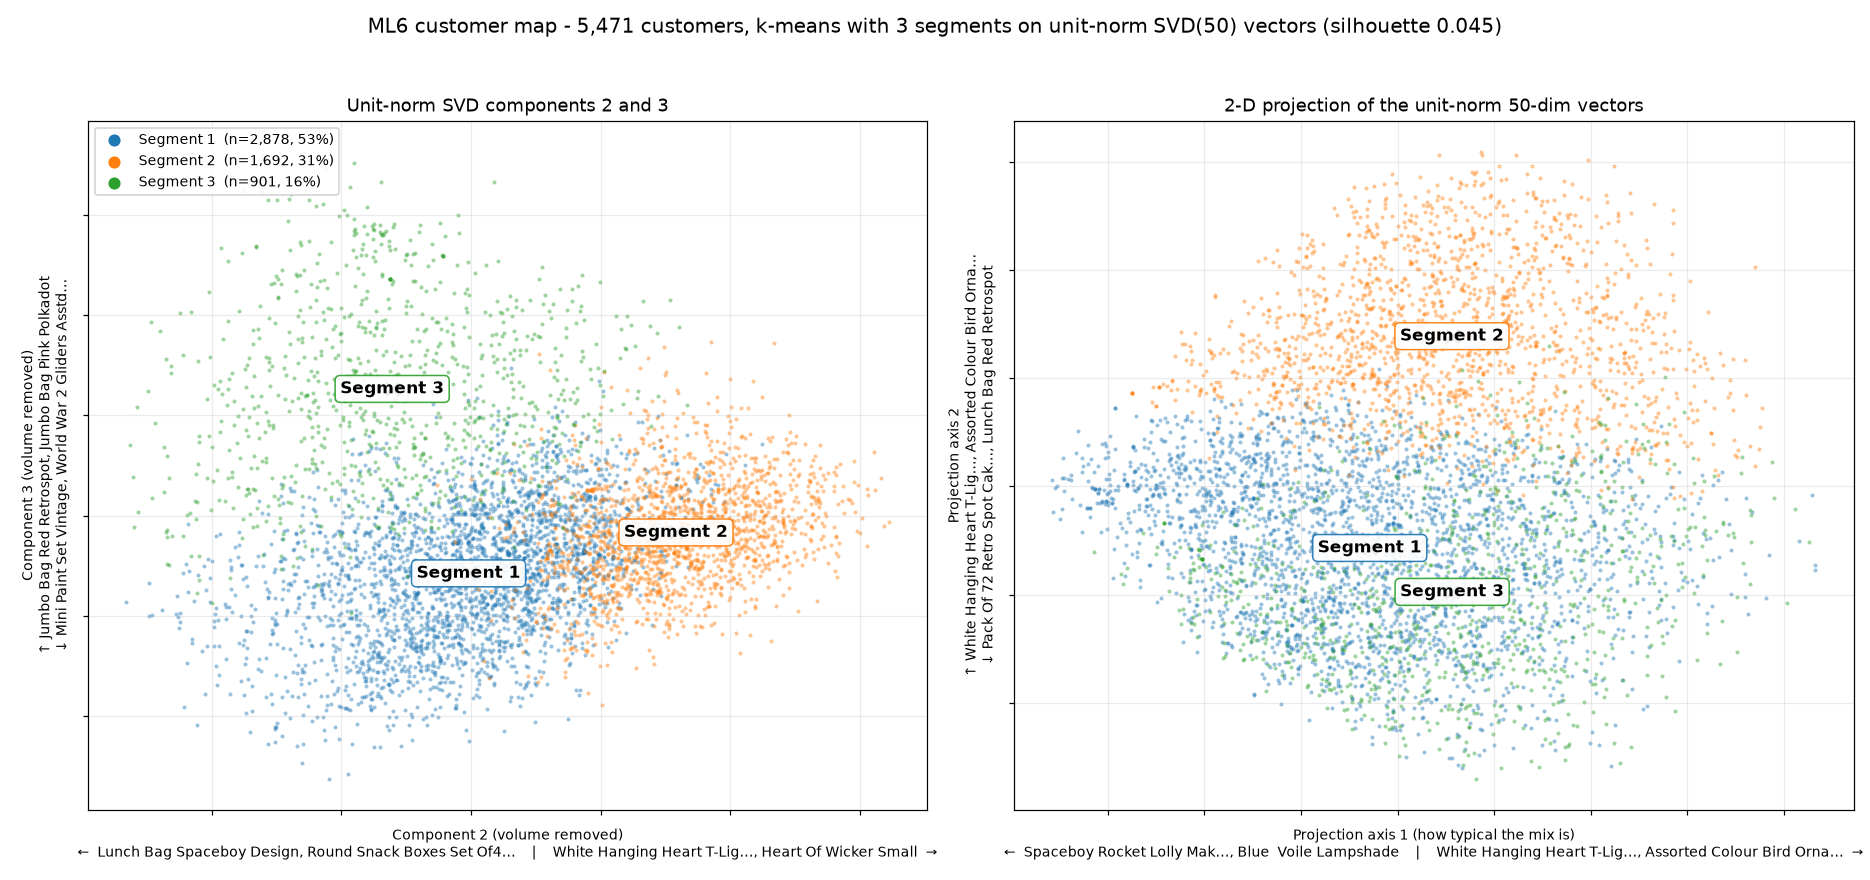

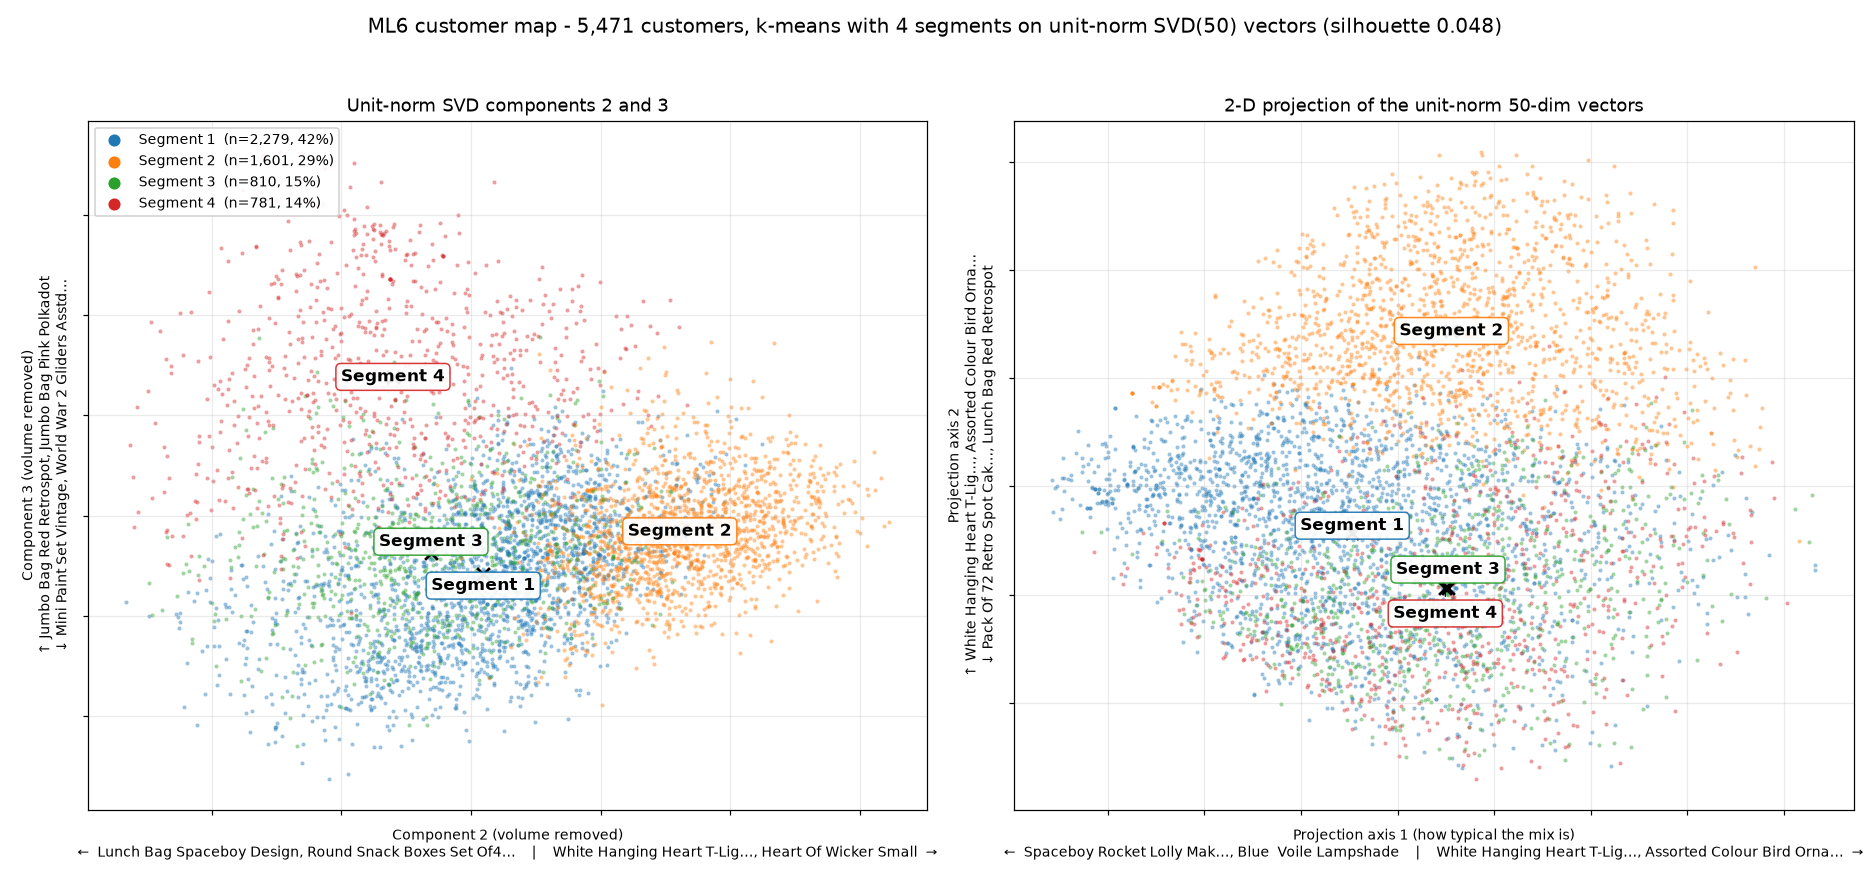

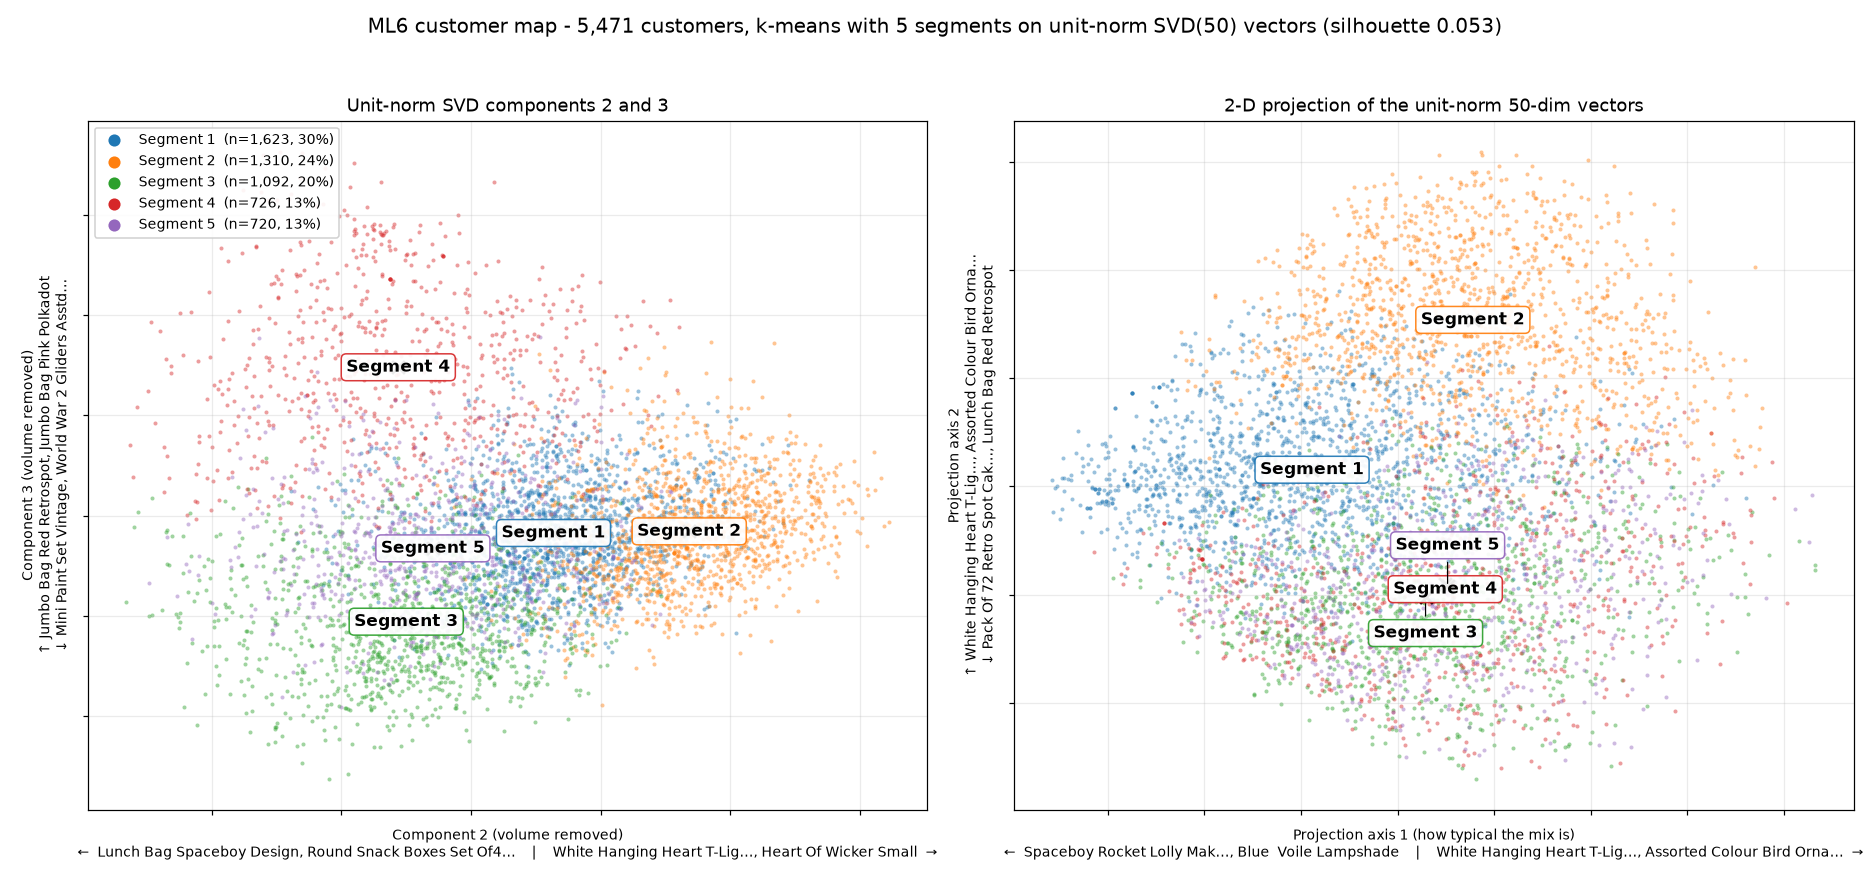

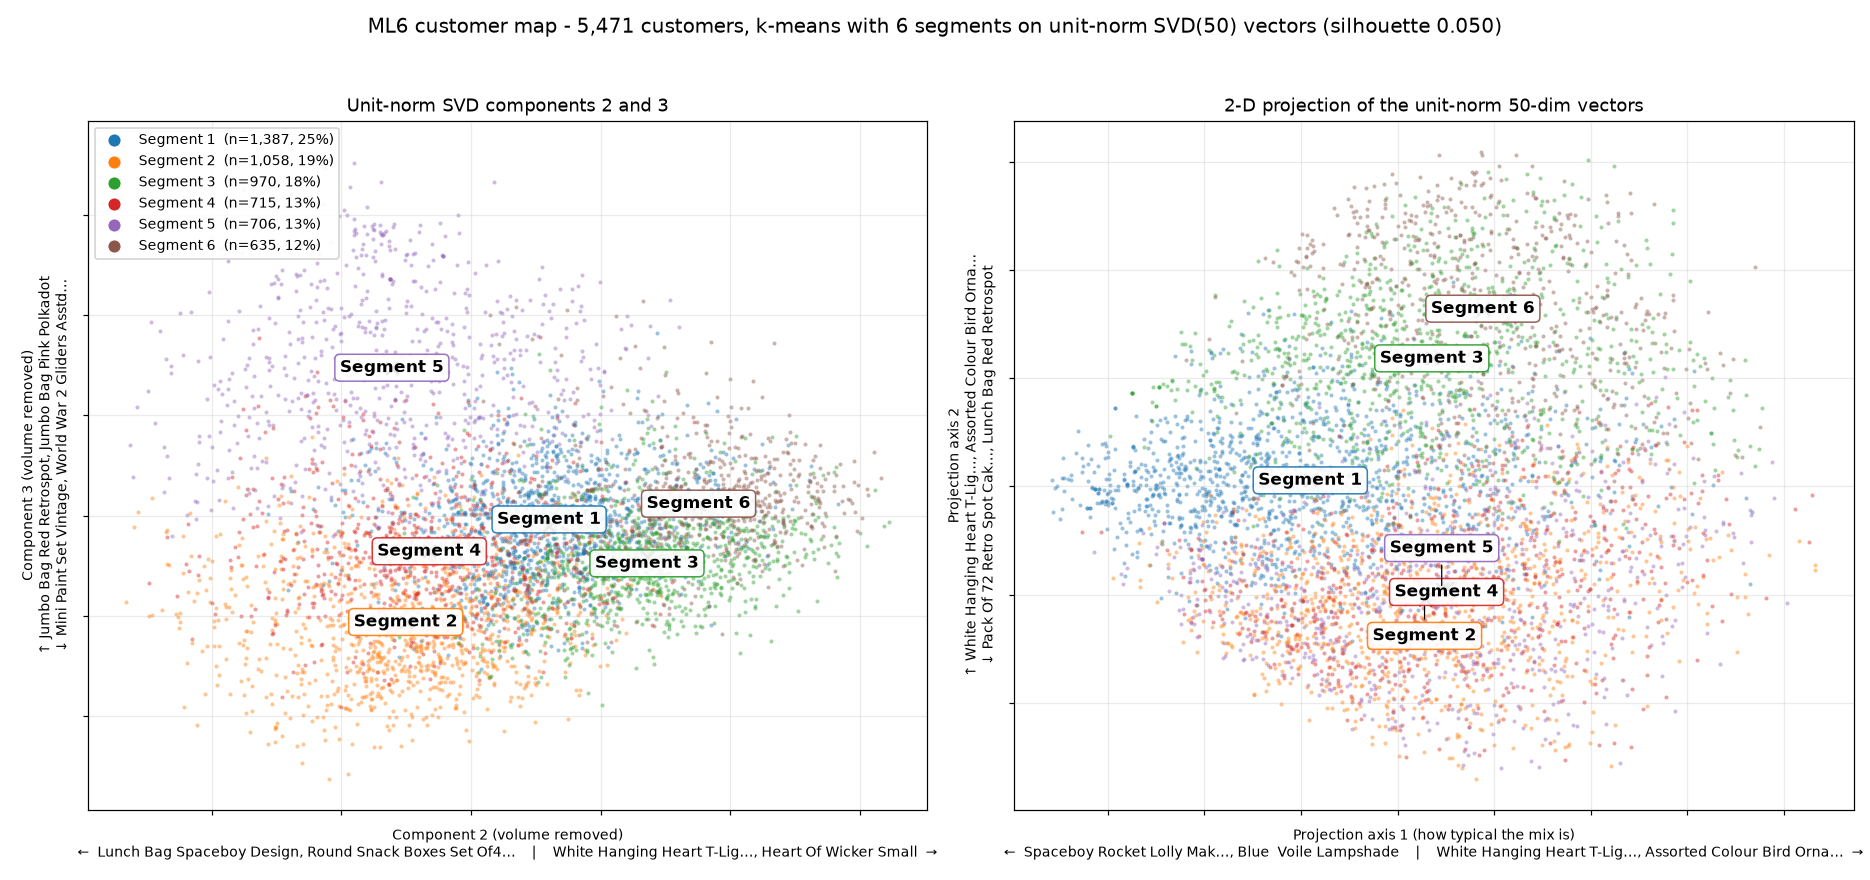

In [7]:
Y2, proj2 = project_2d(X_unit, seed=SEED)
print(f"2-D projection of the unit-norm vectors: explained variance ratio {np.round(proj2.explained_variance_ratio_, 4).tolist()}, "
      f"axis-1 range [{Y2[:,0].min():.3f}, {Y2[:,0].max():.3f}], axis-2 range [{Y2[:,1].min():.3f}, {Y2[:,1].max():.3f}]")

views = [
    ("Unit-norm SVD components 2 and 3", X_unit[:, [1, 2]],
     "Component 2 (volume removed)\n" + component_axis_words(svd, 1, product_index, "x"),
     "Component 3 (volume removed)\n" + component_axis_words(svd, 2, product_index, "y")),
    ("2-D projection of the unit-norm 50-dim vectors", Y2,
     "Projection axis 1 (how typical the mix is)\n" + projection_axis_words(proj2, svd, 0, product_index, "x"),
     "Projection axis 2\n" + projection_axis_words(proj2, svd, 1, product_index, "y")),
]
print("\naxis words (products at each end of the axis):")
for _, _, xl, yl in views:
    print("  x:", xl.replace("\n", " | "))
    print("  y:", yl.replace("\n", " | "))

cmap = plt.get_cmap("tab10")
fig_paths = {}
for n_clusters, labels in labels_by_n.items():
    sizes = pd.Series(labels).value_counts().sort_index()
    fig, axes = plt.subplots(1, 2, figsize=(17, 8))
    for ax, (title, Y, xl, yl) in zip(axes, views):
        for seg in sizes.index:
            msk = labels == seg
            ax.scatter(Y[msk, 0], Y[msk, 1], s=7, alpha=0.45, color=cmap((seg - 1) % 10), linewidths=0,
                       label=f"Segment {seg}  (n={sizes[seg]:,}, {100*sizes[seg]/n:.0f}%)")
        cents = centroids_2d(Y, labels)
        where = spread_labels(cents, Y)           # nudged text positions; centroids themselves are marked with an x
        for seg, c in cents.items():
            ax.scatter(*c, marker="x", s=70, color="black", linewidths=1.8, zorder=5)
            ax.annotate(f"Segment {seg}", xy=c, xytext=where[seg], ha="center", va="center", fontsize=11,
                        fontweight="bold", zorder=6,
                        arrowprops=dict(arrowstyle="-", color="black", lw=0.8) if np.any(where[seg] != c) else None,
                        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec=cmap((seg - 1) % 10), alpha=0.92))
        ax.set_title(title, fontsize=12)
        ax.set_xlabel(xl, fontsize=9)
        ax.set_ylabel(yl, fontsize=9)
        ax.grid(True, alpha=0.25)
        ax.set_xticklabels([]); ax.set_yticklabels([])
    leg = axes[0].legend(loc="upper left", fontsize=9, markerscale=3, framealpha=0.9)
    for h in leg.legend_handles:
        h.set_alpha(1)
    fig.suptitle(f"ML6 customer map - {n:,} customers, k-means with {n_clusters} segments on unit-norm SVD(50) vectors "
                 f"(silhouette {sweep.set_index('n_clusters').loc[n_clusters, 'silhouette']:.3f})", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.95))
    path = FIG_DIR / f"ml6_map_k{n_clusters}.png"
    fig.savefig(path, dpi=110)
    plt.close(fig)
    fig_paths[n_clusters] = path
    print(f"saved -> {path.relative_to(ROOT)}")

for n_clusters, path in fig_paths.items():
    display(Image(filename=str(path), width=1000))

## Stop here

The number of segments and the segment names are decided by the author from the profiles above and recorded in
`decision_log.md`; nothing in this notebook selects them.